# Overview of Mislocalized Variants

In [10]:
import sys
import seaborn as sns
import numpy as np
import polars as pl
from tqdm import tqdm
import matplotlib as mpl
import matplotlib.pyplot as plt
from pycytominer.feature_select import feature_select
from sklearn.decomposition import PCA
import pandas as pd
from matplotlib.patches import Patch
from dynamicTreeCut import cutreeHybrid
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform
import matplotlib.font_manager as fm

# Force TrueType font embedding (Type 42)
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

font_path = "../../../../1_allele_collection/4_manuscript_figures/ARIAL.TTF"
fm.fontManager.addfont(font_path)

font_prop = fm.FontProperties(fname=font_path)
# Set font family to one of the accepted fonts
plt.rcParams.update({
    "font.family": font_prop.get_name(),
    "font.sans-serif": ["ARIAL"],
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})
sns.set_theme(style='white')

# Verify settings
# print(f"pdf.fonttype: {mpl.rcParams['pdf.fonttype']}")
# print(f"ps.fonttype: {mpl.rcParams['ps.fonttype']}")
# print(f"font.family: {mpl.rcParams['font.family']}")

sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../../..")
from analyses_plot_utils import *

FEATURE_IMPORTANCE_THRES = 0.01
SIGNALING_DOMAINS = [
    "g2p_Signal (UniProt)",
    "g2p_Transit peptide (UniProt)",
    "g2p_Transmembrane (UniProt)",
    "g2p_Topological domain (UniProt)",
    "g2p_Intramembrane (UniProt)",
    "g2p_Lipidation (UniProt)"
]
META_COLS = [
    "gene_variant",
    "Metadata_Bio_Batch",
    "img_pheno_score",
    "img_misloc_score",
    "img_pheno_hit",
    "img_misloc_hit",
    "clinvar_clnsig_clean",
    "clinvar_clnsig_clean_pp_strict",
    "clinvar_OMIM_id",
    "OMIM_IDs",
    "OMIM_disease_names",
    "disease_modules",
    "inheritance_pattern",
    "plddt_f32",
    "rsa_f32", 
    "pLDDT_Category",
    "RSA_Category",
] + SIGNALING_DOMAINS

## 1. Loading Data

In [2]:
ref_var_cell_all_prof_df = pl.read_parquet("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc.parquet")
feat_adj_df = pl.read_csv("../../3_outputs/feat_importance_adj_gt1e-3_all_alleles.csv")

In [3]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=100000)
imaging_summary_clinvar_misloc_hits = imaging_summary_clinvar.filter(
    pl.col("img_misloc_hit"),
)
misloc_alleles = imaging_summary_clinvar_misloc_hits["gene_variant"].to_list()
print("Protein mislocalized alleles:", len(misloc_alleles))

## Protein abundance change
imaging_summary_clinvar_abund_chg = imaging_summary_clinvar.filter(
    (pl.col("U2OS_prot_abun_t_stat").is_not_null()) & (pl.col("U2OS_prot_abun_t_pval") < 0.05/943)
)
prot_abund_chg_alleles = imaging_summary_clinvar_abund_chg["gene_variant"].to_list()

# ax = sns.regplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     y="AUROC_Mean_GFP_ADJ"
# )
# ax.set_xlim(0.45, 1.05)
# ax.set_ylim(0.45, 1.05)
# plt.show()

# ax = sns.regplot(
#     data=imaging_summary_clinvar.filter(
#         (pl.col("AUROC_Mean_GFP")>.9) | (pl.col("AUROC_Mean_GFP_ADJ")>.9)
#     ).to_pandas(),
#     x="AUROC_Mean_GFP",
#     y="AUROC_Mean_GFP_ADJ"
# )
# ax.set_xlim(0.825, 1.005)
# ax.set_ylim(0.825, 1.005)
# plt.show()

Protein mislocalized alleles: 112


## 2. Mislocalized Variants Analyses

In [4]:
misloc_var_sig_feat_df = feat_adj_df.filter(
    # pl.col(col).is_in(pl.col(col).top_k(TOP_NUM_FEAT_MISLOC_VAR))
    pl.max_horizontal(misloc_alleles) > FEATURE_IMPORTANCE_THRES
)
get_sig_feats_misloc_alleles = misloc_var_sig_feat_df["cp_feature"].to_list()

In [5]:
norm_misloc_vars_feat_df, norm_var_sc_feat_df = pl.DataFrame(), pl.DataFrame()
sig_diff_feat = [feat for feat in get_sig_feats_misloc_alleles if feat in ref_var_cell_all_prof_df.columns] #[feat for feat in get_top_feats if feat in ref_var_cell_all_prof_df.columns]

for gene in tqdm(imaging_summary_clinvar_misloc_hits["Gene"].unique().to_list()):
    gene_mean = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).mean().to_numpy()[0].tolist()
    gene_std = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).std().to_numpy()[0].tolist()

    # print(gene, np.mean(gene_mean), np.min(gene_std))
    z_norm_var_sc_feat_df = ref_var_cell_all_prof_df.filter(
        (pl.col("Metadata_gene_allele").str.starts_with(f"{gene}_"))
        &(pl.col("Metadata_gene_allele")!=gene)
        &(pl.col("Metadata_gene_allele").is_in(imaging_summary_clinvar_misloc_hits["gene_variant"].unique()))
    ).with_columns(
        [((pl.col(col) - pl.lit(gene_mean[i])) / pl.lit(gene_std[i])).alias(col)
        for i, col in enumerate(sig_diff_feat)]
    )
    norm_var_sc_feat_df = pl.concat([
        norm_var_sc_feat_df,
        z_norm_var_sc_feat_df
    ])
    z_norm_var_feat_df = z_norm_var_sc_feat_df.group_by(
        "Metadata_gene_allele", "Metadata_Plate", "Metadata_Well" ## aggregate by well first
    ).agg(
        pl.col(col).median().alias(col)
        for col in sig_diff_feat
    ).group_by(
        "Metadata_gene_allele" ## aggregate by allele
    ).agg(
        pl.col(col).median().alias(col)
        for col in sig_diff_feat
    )#.to_pandas().set_index("Metadata_gene_allele")[sig_diff_feat]

    norm_misloc_vars_feat_df = pl.concat(
        [norm_misloc_vars_feat_df, z_norm_var_feat_df],
         how="diagonal"
    )

100%|██████████| 40/40 [00:09<00:00,  4.25it/s]


In [6]:
# Standardize the features before PCA
# var_zscore_feat_gfp_filtered_int_df = inverse_normal_transform(norm_vars_feat_df)
var_zscore_feat_gfp_filtered_int_df = norm_misloc_vars_feat_df.to_pandas()#.set_index("Metadata_gene_allele")

# 2. Apply Winsorization (Clipping)
# We clip values at -5 (lower) and +5 (upper)
# var_zscore_feat_gfp_filtered_int_df = var_zscore_feat_gfp_filtered_int_df.clip(lower=-5, upper=5).reset_index()

## feature selection
var_zscore_feat_gfp_filtered_int_feat_sel_df = feature_select(
    var_zscore_feat_gfp_filtered_int_df, operation="variance_threshold"
)
var_zscore_feat_gfp_filtered_int_feat_sel_df = pl.DataFrame(
    feature_select(var_zscore_feat_gfp_filtered_int_feat_sel_df, operation="correlation_threshold")
)

var_zscore_feat_gfp_filtered_int_feat_sel_df = var_zscore_feat_gfp_filtered_int_feat_sel_df.join(
    imaging_summary_clinvar.select(META_COLS).rename(
        {k: f"Metadata_{k}" for k in META_COLS if "Metadata" not in k}
    ),
    left_on="Metadata_gene_allele",
    right_on="Metadata_gene_variant",
    how="inner"
)

In [7]:
# ----------------------------------------------------------------------
# 1. Data Preparation + PCA
# ----------------------------------------------------------------------
df_meta = var_zscore_feat_gfp_filtered_int_feat_sel_df.to_pandas().set_index("Metadata_gene_allele")
df = df_meta[[c for c in df_meta.columns if "Metadata_" not in c]]
metadata_cols = [c for c in df_meta.columns if "Metadata_" in c]

pca = PCA(n_components=0.90, random_state=42)
data_pca = pca.fit_transform(df)

Minimum cluster size: 7
..cutHeight not given, setting it to 30.629559555597826  ===>  99% of the (truncated) height range in dendro.
..done.


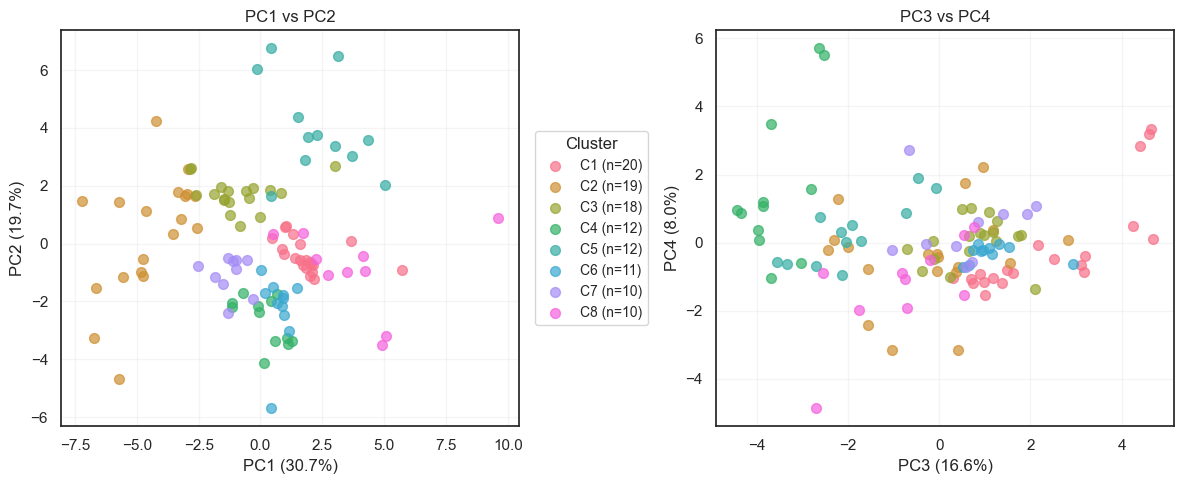

In [8]:
# ----------------------------------------------------------------------
# 2. Hierarchical Clustering on PCA
# ----------------------------------------------------------------------
Z = linkage(data_pca, method='ward', metric='euclidean')
dist_matrix = pdist(data_pca, metric='euclidean')
linkage_matrix_pca = linkage(data_pca, method='ward', optimal_ordering=True) ##

# Dynamic tree cut - adapts to tree structure with minimum cluster size
# minClusterSize: minimum number of samples per cluster (key parameter)
min_cluster_size = 7 ## SAME as phenotype variants #max(5, len(data_pca) // 20)
print(f"Minimum cluster size: {min_cluster_size}")

cluster_labels = cutreeHybrid(
    Z,
    dist_matrix,
    minClusterSize=min_cluster_size,
    deepSplit=2,
)["labels"]

n_clusters = len(set(cluster_labels))
colors = sns.color_palette("husl", n_clusters)
unique_labels = sorted(np.unique(cluster_labels))
color_map = {label: colors[i] for i, label in enumerate(unique_labels)}

# ----------------------------------------------------------------------
# 3. Plot 1: PCA Scatter (PC1/PC2 and PC3/PC4)
# ----------------------------------------------------------------------
n_pcs = data_pca.shape[1]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# PC1 vs PC2
for c in unique_labels:
    mask = cluster_labels == c
    axes[0].scatter(
        data_pca[mask, 0], 
        data_pca[mask, 1],
        c=[color_map[c]], 
        label=f'C{c} (n={mask.sum()})',
        alpha=0.7,
        s=50
    )
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[0].set_title('PC1 vs PC2')
axes[0].legend(bbox_to_anchor=(1.02, 0.5), loc='center left', fontsize=10, title="Cluster")
axes[0].grid(alpha=0.2)

# PC3 vs PC4
if n_pcs >= 4:
    for c in unique_labels:
        mask = cluster_labels == c
        axes[1].scatter(
            data_pca[mask, 2], 
            data_pca[mask, 3],
            c=[color_map[c]], 
            label=f'C{c} (n={mask.sum()})',
            alpha=0.7,
            s=50
        )
    axes[1].set_xlabel(f'PC3 ({pca.explained_variance_ratio_[2]:.1%})')
    axes[1].set_ylabel(f'PC4 ({pca.explained_variance_ratio_[3]:.1%})')
    axes[1].set_title('PC3 vs PC4')
    axes[1].grid(alpha=0.2)
else:
    axes[1].text(0.5, 0.5, f'Only {n_pcs} PCs available', ha='center', va='center')
    axes[1].set_title('PC3 vs PC4 (unavailable)')

plt.tight_layout()
plt.show()

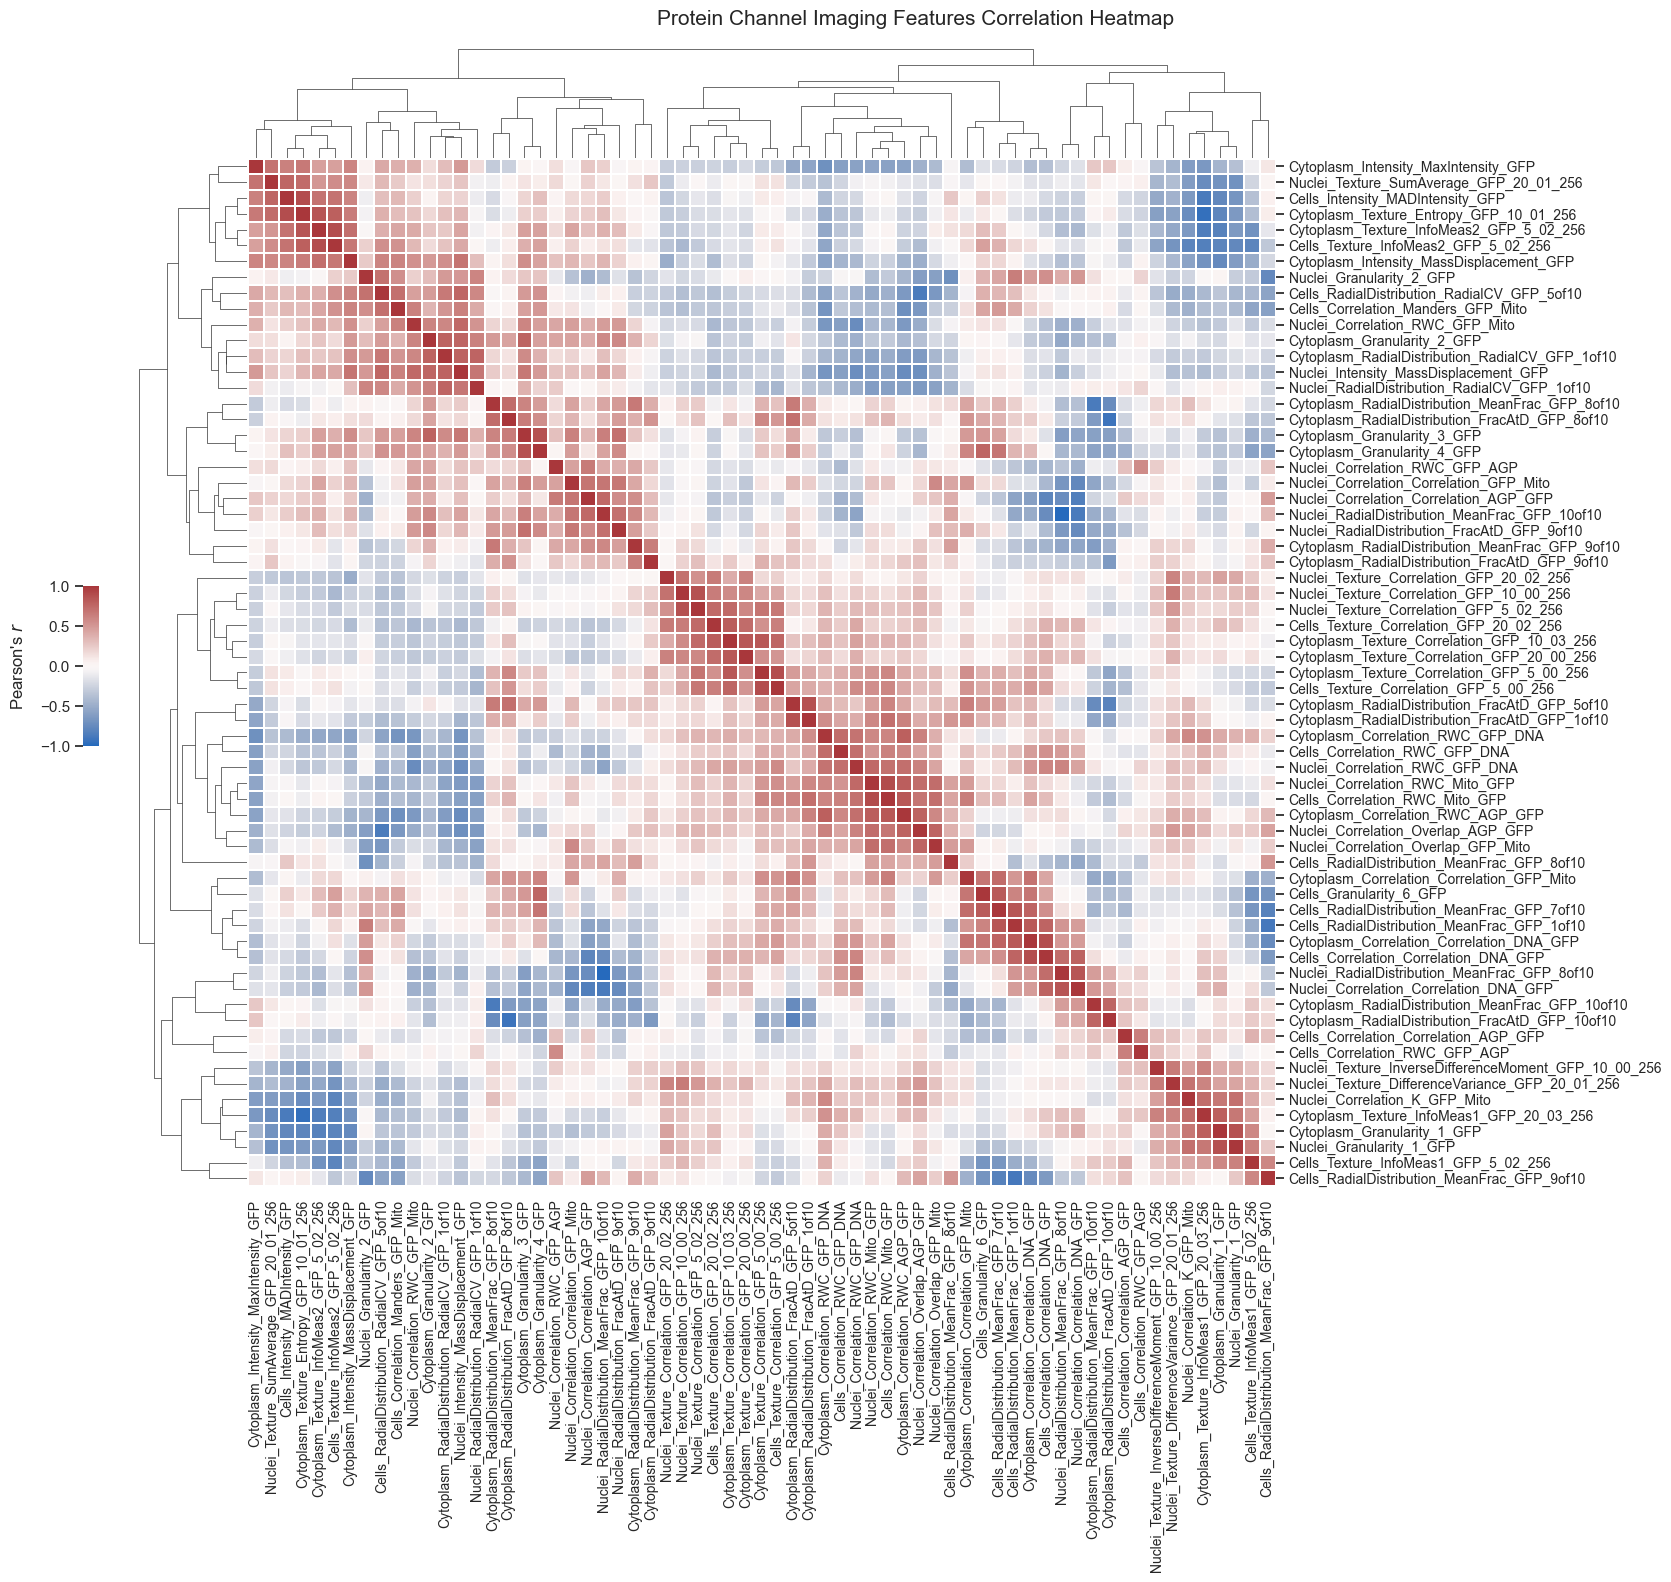

In [11]:
# Correlation clustermap (run first to get column linkage)
# Correlation clustermap with optimal leaf ordering
corr_df = df.corr()

# Convert correlation to distance (1 - r), then to condensed form
corr_dist = 1 - corr_df.values
np.fill_diagonal(corr_dist, 0)  # Ensure diagonal is 0
corr_dist_condensed = squareform(corr_dist)

# Compute linkage with optimal ordering
col_linkage = linkage(corr_dist_condensed, method='average', optimal_ordering=True)

g_corr = sns.clustermap(
    data=corr_df,
    cmap="vlag", vmin=-1,
    row_linkage=col_linkage,
    col_linkage=col_linkage,
    cbar_pos=(-.02, 0.55, 0.01, 0.1),
    yticklabels=1, xticklabels=1,
    # square=True,
    figsize=(16, 16),
    linewidth=.05,
    dendrogram_ratio=(0.1, 0.1),
    
)
g_corr.fig.suptitle("Protein Channel Imaging Features Correlation Heatmap", fontsize=15, y=1.01)
g_corr.cax.yaxis.set_label_position('left')
g_corr.cax.yaxis.set_ticks_position('left')
g_corr.cax.set_ylabel(r"Pearson's $r$", labelpad=10)
g_corr.ax_heatmap.set_xticklabels(g_corr.ax_heatmap.get_xticklabels(), fontsize=10)
g_corr.ax_heatmap.set_yticklabels(g_corr.ax_heatmap.get_yticklabels(), fontsize=10)
plt.show()

# Extract column linkage and order
col_order = list(corr_df.columns[g_corr.dendrogram_col.reordered_ind])

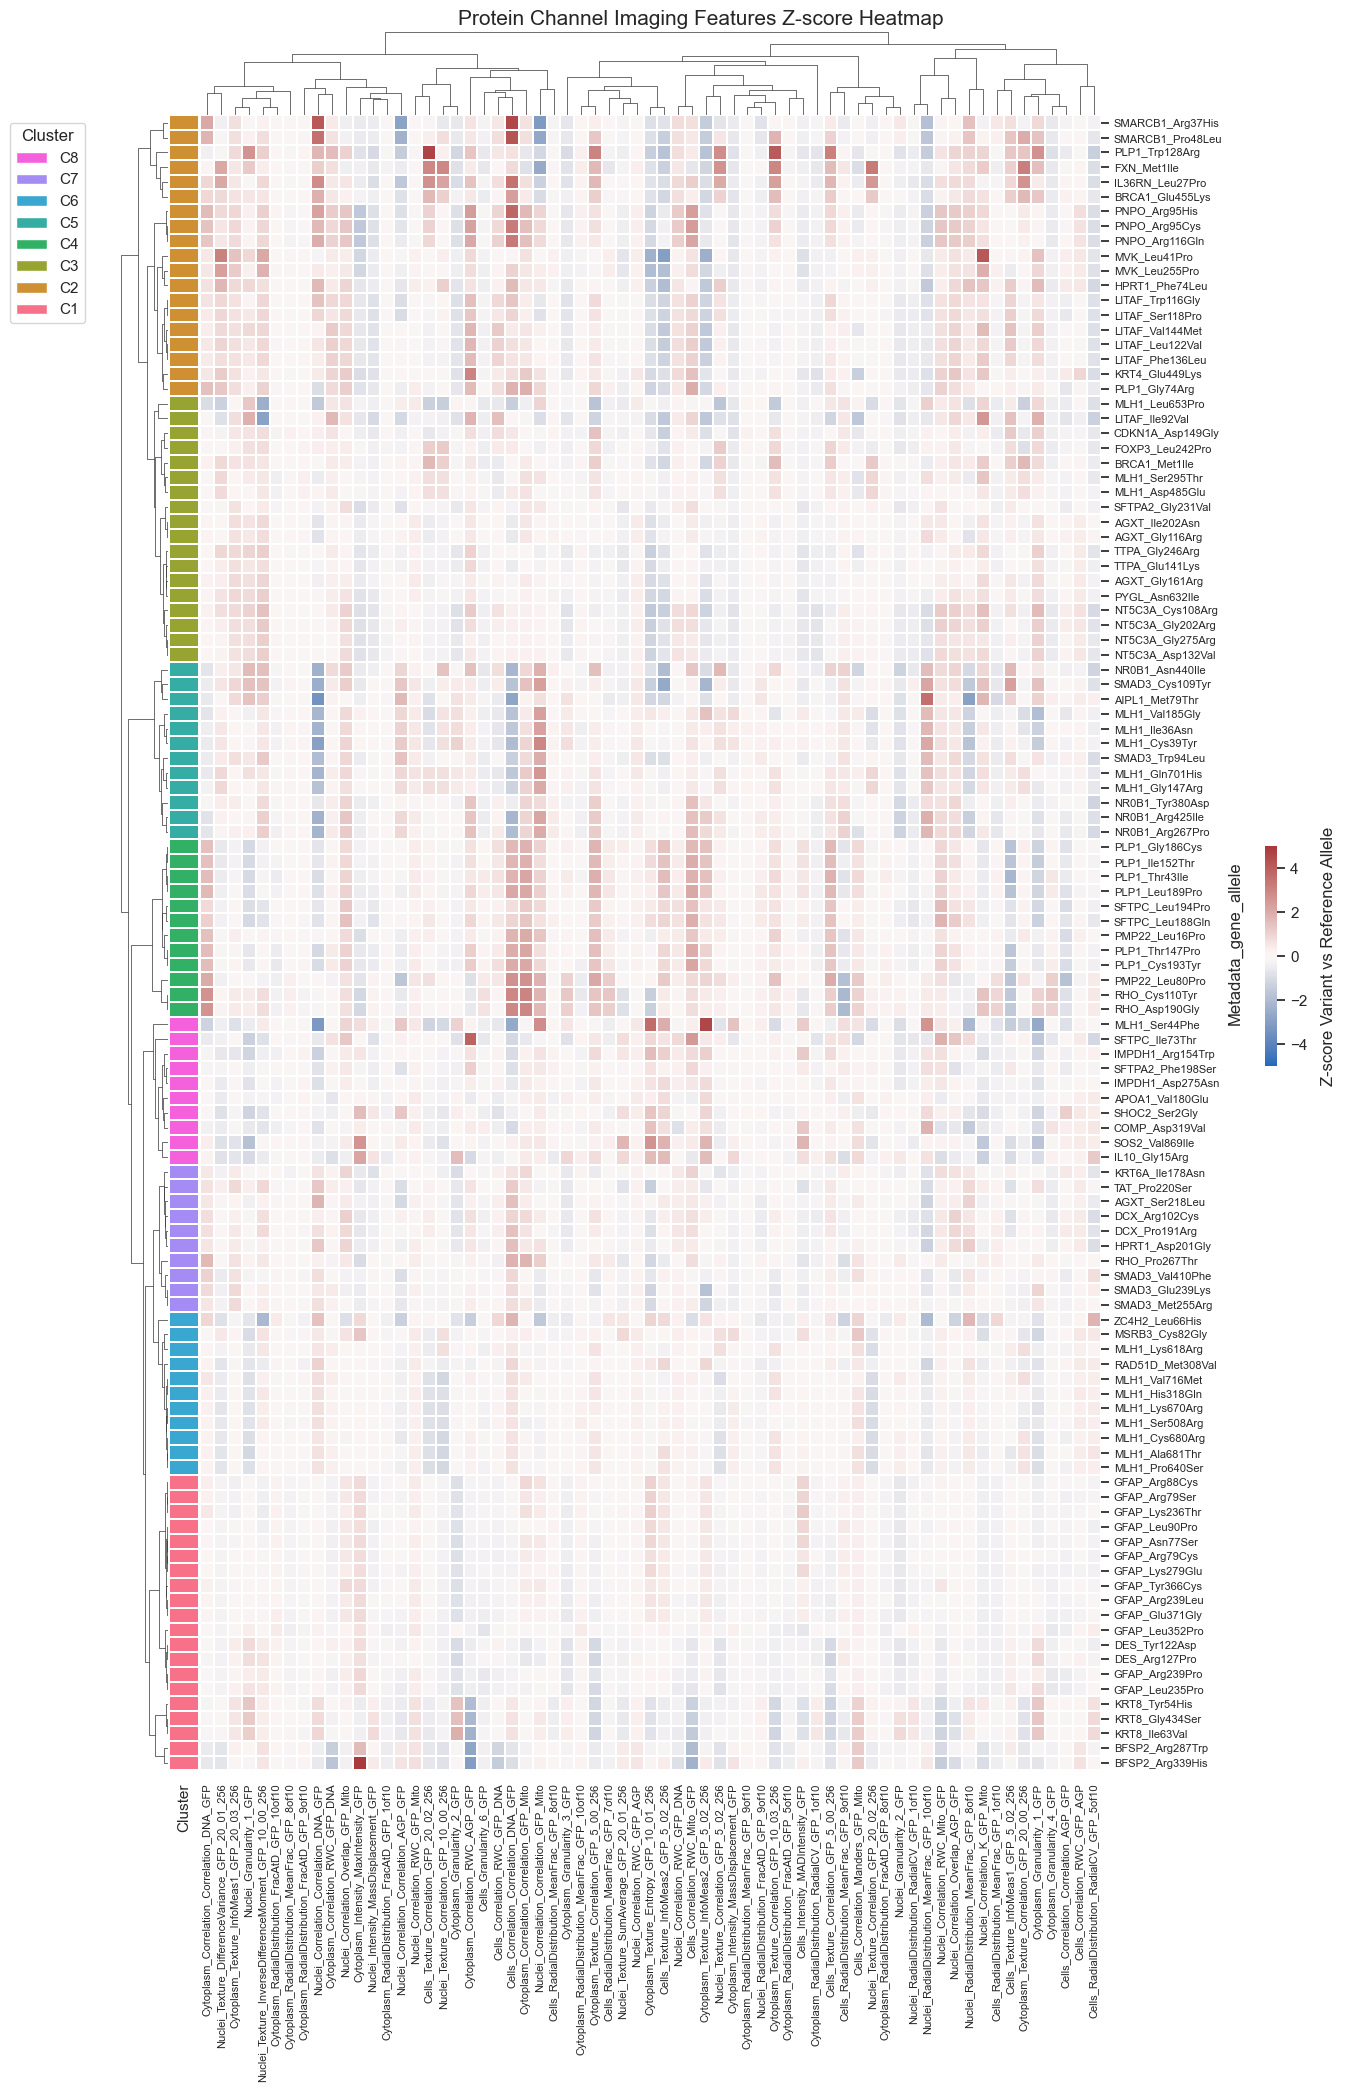

In [12]:
# ----------------------------------------------------------------------
# 4. Plot 2: Clustermap with PCA-based Dendrogram
# ----------------------------------------------------------------------
# Row colors from cluster assignment
row_colors_series = pd.Series(
    [color_map[c] for c in cluster_labels], 
    index=df.index, 
    name='Cluster'
)

# Main clustermap with correlation-based column dendrogram
g = sns.clustermap(
    data=df[col_order],  # Reorder columns to match
    cmap="vlag",
    center=0, vmin=-np.ceil(df[col_order].max().max()), 
    vmax=np.ceil(df[col_order].max().max()),
    row_colors=row_colors_series,
    row_linkage=Z,
    col_linkage=col_linkage,  # Use correlation-based linkage
    figsize=(12, 22),
    yticklabels=1,
    xticklabels=1,
    linewidths=0.05,
    cbar_pos=(.97, 0.52, 0.01, 0.1),
    dendrogram_ratio=(0.05, 0.05)
)

g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), fontsize=8, rotation=90)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=8)
g.cax.set_ylabel(r"Z-score Variant vs Reference Allele", labelpad=10)
g.fig.suptitle("Protein Channel Imaging Features Z-score Heatmap", fontsize=15, y=1)

legend_handles = [Patch(facecolor=color_map[c], label=f'C{c}') 
                  for c in sorted(color_map.keys(), reverse=True)]
g.ax_heatmap.legend(
    handles=legend_handles,
    title='Cluster',
    bbox_to_anchor=(-0.22, 1.0),
    loc='upper left',
    frameon=True
)
plt.show()

In [13]:
# ----------------------------------------------------------------------
# 5. Results DataFrame
# ----------------------------------------------------------------------
dr_res_df = df_meta.copy()
dr_res_df["Metadata_cluster"] = cluster_labels

dr_res_df.to_csv("../../3_outputs/misloc_var_clustering_results.csv")